# Defensive Alignment Causal RL — Pipeline Walkthrough

Every defense in the league, every snap — runs included. Before the ball is snapped a
coordinator commits to an **alignment**: which personnel package is on the field (base,
nickel, dime) and how many defenders stand in the box. Both are chosen pre-snap and both
are charted on essentially every play, so this is an action a coordinator can actually
call and we can actually observe.

The pipeline recommends an alignment for each situation and evaluates that recommendation
from logged games alone. The central difficulty is that the offense *responds* to the
alignment — load the box and it throws; show dime and it runs — so the value of a call is
a mixture over the offense's response, not the outcome of one branch. And coordinators
choose alignments for reasons the data never recorded, which affect outcomes too.

Every estimate below is stamped with the causal graph it assumed, and every headline claim
is checked against a simulated league whose true answer is known.

## Setup

In [1]:
import os, sys, warnings, logging
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)

here = os.getcwd()
root = here if os.path.exists(os.path.join(here, "configs")) else os.path.dirname(here)
os.chdir(root); sys.path.insert(0, root)

from src.data.load import (load_pbp, load_ftn, merge_ftn, ftn_coverage,
                           generate_synthetic_alignment, true_alignment_value)
from src.data.features import (assert_ftn_coverage, build_dataset, time_aware_split,
                               PACKAGES, FRONTS)
from src.scm import graph as scm
from src.scm import identify
from src.models.behavior.propensity import fit_behavior_model
from src.models.outcome.q_model import fit_q_model, crossfit_q, fit_q_ensemble
from src.ope.direct_method import behavior_recovery_check
from src.ope.doubly_robust import dr_policy_value
from src.ope.ladder import ope_ladder
from src.ope.sensitivity import sensitivity_bounds, attach as attach_sensitivity
from src.policy.safe import learn_safe_policy
from src.evaluation import compare_to_baseline

# Chart tokens: validated categorical slots (blue, orange, aqua), ink for text,
# a recessive grid. Aqua sits below 3:1 contrast, so it only marks directly-labeled items.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:+.4f}")

cfg = yaml.safe_load(open("configs/v3.yaml"))
graph = scm.graph_for(cfg); gv = graph.version_tag()
clip = cfg["ope"]["weight_clip"]
print("graph:", gv)

graph: v3.2+8e2de51a8e2b


## Step 1 — Data: every defense, every snap

Play-by-play from nflfastR, pre-snap charting from FTN. Personnel comes from nflfastR's
participation data; the box count from FTN. A snap enters the sample if both are charted —
which is ~99.5% of scrimmage snaps, runs and passes alike.

In [2]:
S = cfg["data"]["seasons"]
pbp = merge_ftn(load_pbp(S, cfg["data"]["cache_dir"]), load_ftn(S, cfg["data"]["cache_dir"]))
assert_ftn_coverage(pbp, cfg)
ds = build_dataset(pbp, cfg)
d = ds.df
print(f"{len(d):,} snaps · {d['defteam'].nunique()} defenses · seasons {S} · "
      f"{(d['play_type'] == 'run').mean():.1%} runs")
align = (d.groupby("action_label")
          .agg(snaps=("reward", "size"), run_rate=("play_type", lambda x: (x == "run").mean()))
          .reindex(ds.action_labels.values()))
align["share"] = align["snaps"] / align["snaps"].sum()
align[["snaps", "share", "run_rate"]].style.format({"snaps": "{:,}", "share": "{:.1%}", "run_rate": "{:.0%}"})

139,670 snaps · 32 defenses · seasons [2022, 2023, 2024, 2025] · 42.6% runs


,snaps,share,run_rate
action_label,,,
base_box_le5,"2,005",1.4%,30%
base_box6,"9,855",7.1%,54%
base_box7,"16,934",12.1%,65%
base_box_ge8,"7,369",5.3%,75%
nickel_box_le5,"14,972",10.7%,17%
nickel_box6,"54,102",38.7%,39%
nickel_box7,"16,661",11.9%,53%
nickel_box_ge8,"3,079",2.2%,71%
dime_plus_box_le5,"7,966",5.7%,12%


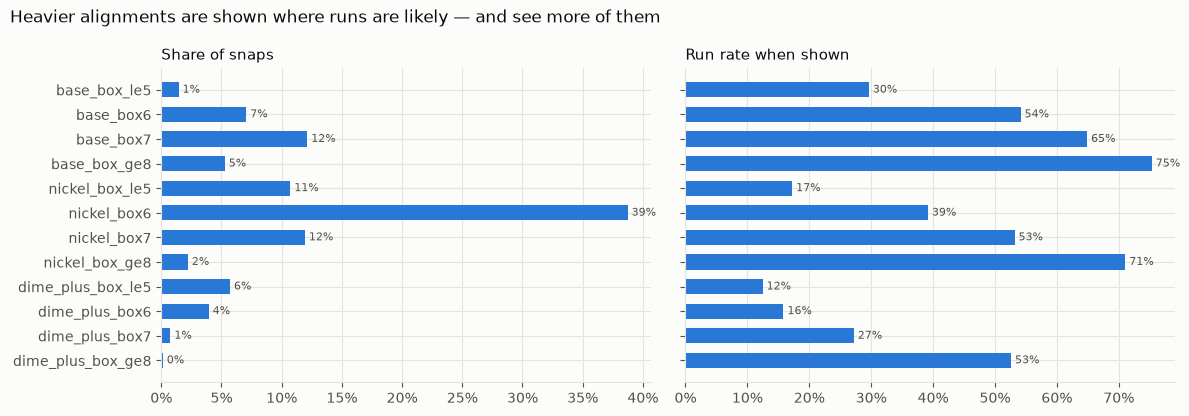

In [3]:
# Two measures on different scales -> two panels, never one chart with two axes.
order = list(ds.action_labels.values())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title, fmt in [(axes[0], "share", "Share of snaps", "{:.0%}"),
                            (axes[1], "run_rate", "Run rate when shown", "{:.0%}")]:
    ax.barh(order, align.loc[order, col], color=BLUE, height=0.62)
    for y, v in enumerate(align.loc[order, col]):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=INK2)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].invert_yaxis()
fig.suptitle("Heavier alignments are shown where runs are likely — and see more of them",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

The run rate climbs from ~13% against dime with a light box to ~75% against base with eight
or more in the box. That gradient is *two things at once*: coordinators show heavy looks when
they expect a run (selection), and offenses check away from a loaded box (deterrence).
Untangling them is the whole job — which is why a raw comparison of these rates would say
nothing about what an alignment *does*.

In [4]:
train, test = time_aware_split(ds, cfg["data"]["holdout_season"])
print(f"train {len(train.df):,} snaps (< {cfg['data']['holdout_season']}) · "
      f"holdout {len(test.df):,} (>= {cfg['data']['holdout_season']})")

train 105,221 snaps (< 2025) · holdout 34,449 (>= 2025)


## Step 2 — The causal graph

The treatment is the alignment. Two variables sit *downstream* of it and so must not be
adjusted for: the offense's run/pass choice (it responds to the look) and the coverage
the coordinator pairs with the alignment. A third is **execution** — everything decided after
the snap: pass rush, coverage technique, blocking, tackling, the quarterback's accuracy. It is
what turns a call and a set of players into a result, so it sits between them and EPA, and it
is unobserved here. The estimand is the alignment's **total** effect, travelling through all
three.

Team identity is a confounder — a defense's roster and scheme drive its calls and its outcomes
— and so is current quality, proxied by recency-weighted historical EPA for the quarterback,
the defense, and the offense as a unit (a half-life of ~250 plays, chosen because it best
predicted each offense's next game). The coordinator's hidden read is the unobserved confounder
the sensitivity analysis bounds.

The read is a read *of* something: the offense's **plan** — what it means to run before it
breaks the huddle. The plan is never recorded (the run/pass call in the data is what the
offense did, after any check at the line), but it shapes the personnel and formation the
offense shows, the call it runs, and what the coordinator expects. That opens a path the
adjustment set cannot close: alignment ← read ← plan → run/pass → EPA. A coordinator who reads
a run loads the box, and runs are cheap for a defense, so a heavy box is credited with
outcomes the read earned. The data shows the footprint: heavy boxes face *more* runs than
the pre-snap state predicts, where deterrence alone would predict fewer. The plan adds nothing
to adjust for — it only names the bias — and it makes splitting an alignment's effect by run
versus pass a mistake: the run/pass call is now a descendant of the confounder.

SCM — personnel package x front, every snap [v3.2+8e2de51a8e2b]
  treatment=def_alignment, outcome=epa
  adjustment set (condition on): ['game_state', 'off_formation', 'off_personnel', 'off_tendencies', 'player_proxies', 'team_identity']
    -> 28 feature columns
  mediators (do NOT condition on): ['def_coverage', 'execution', 'off_playcall']
  unobserved confounders: ['coach_read', 'execution', 'offense_intent'] (bounded by the sensitivity analysis)
    no dropback selection: every FTN- and personnel-charted scrimmage snap, runs included


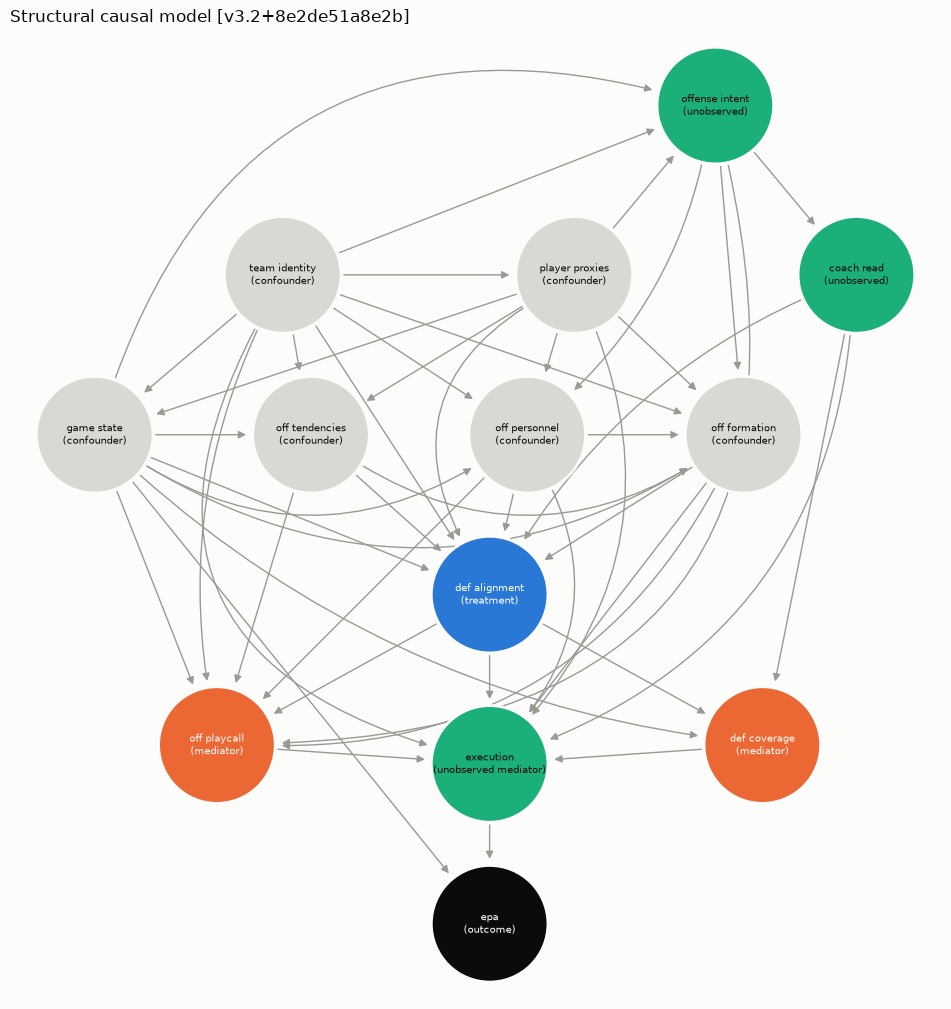

In [5]:
print(graph.describe())
from matplotlib.patches import Circle, FancyArrowPatch
# Layered: identity and quality, the offense's pre-snap presentation, the call,
# what happens after the snap, the result.
pos = {"offense_intent": (2.4, 5.5),
       "team_identity": (-2.2, 3.7), "player_proxies": (0.9, 3.7), "coach_read": (3.9, 3.7),
       "game_state": (-4.2, 2.0), "off_tendencies": (-1.9, 2.0), "off_personnel": (0.4, 2.0),
       "off_formation": (2.7, 2.0), "def_alignment": (0.0, 0.3),
       "off_playcall": (-2.9, -1.3), "execution": (0.0, -1.5), "def_coverage": (2.9, -1.3),
       "epa": (0.0, -3.2)}
R = 0.62  # node radius, data units (equal aspect keeps data and screen geometry aligned)

def _curve(p0, p2, rad, n=60):
    p0, p2 = np.asarray(p0, float), np.asarray(p2, float)
    c = (p0 + p2) / 2 + rad * np.array([p2[1] - p0[1], -(p2[0] - p0[0])])
    t = np.linspace(0.05, 0.95, n)[:, None]
    return (1 - t) ** 2 * p0 + 2 * (1 - t) * t * c + t ** 2 * p2, c

def _route(s, t):
    """Smallest curvature that keeps an edge clear of every node it doesn't touch —
    an edge through an untouched node reads as a causal claim that isn't there."""
    others = [np.asarray(p) for n, p in pos.items() if n not in (s, t)]
    def clear(r): return min(np.linalg.norm(_curve(pos[s], pos[t], r)[0] - o, axis=1).min() for o in others)
    for r in (0, .15, -.15, .3, -.3, .45, -.45, .6, -.6):
        if clear(r) > R * 1.08: return r
    return max((0, .3, -.3, .6, -.6), key=clear)

role = {graph.treatment: (BLUE, "white", "treatment"), graph.outcome: (INK, "white", "outcome")}
role |= {m: (ORANGE, "white", "mediator") for m in graph.mediators}
role |= {u: (AQUA, INK, "unobserved") for u in graph.unobserved}
role[scm.EXECUTION] = (AQUA, INK, "unobserved mediator")
fig, ax = plt.subplots(figsize=(11, 10.2)); ax.grid(False); ax.axis("off")
ax.set_xlim(-5.1, 4.8); ax.set_ylim(-4.0, 6.3); ax.set_aspect("equal")
for s, t in graph.edges:
    rad = _route(s, t); _, c = _curve(pos[s], pos[t], rad)
    p0, p2 = np.asarray(pos[s], float), np.asarray(pos[t], float)
    a = p0 + R * (c - p0) / np.linalg.norm(c - p0); b = p2 + (R + 0.04) * (c - p2) / np.linalg.norm(c - p2)
    ax.add_patch(FancyArrowPatch(a, b, connectionstyle=f"arc3,rad={rad}", arrowstyle="-|>",
                                 mutation_scale=11, lw=1.0, color="#9a9994", zorder=1))
for n, (x, y) in pos.items():
    fc, tc, tag = role.get(n, ("#d9d8d2", INK, "confounder"))
    ax.add_patch(Circle((x, y), R, facecolor=fc, edgecolor=SURFACE, lw=2, zorder=3))
    ax.text(x, y, f"{n.replace('_', ' ')}\n({tag})", ha="center", va="center", fontsize=7.5, color=tc, zorder=4)
ax.set_title(f"Structural causal model [{gv}]", loc="left", fontsize=12)
plt.tight_layout(); plt.show()

### Testing the graph against the data

A hand-drawn graph is a set of claims, and the missing edges are the strong ones: each implies a
conditional independence that data can refute. Below, every such claim is tested — with an effect
size, because at 10⁵ snaps almost any dependence is "significant" — along with how much each
variable feeding the outcome still explains given the others.

The graph was revised on the training seasons (a first version failed 11 of its 12 testable
claims, all for missing edges among the confounders: teams have schemes, current quality drives
the score, down and distance drive run/pass). Testing a revision on the data that prompted it is
circular, so the held-out season is used here to **confirm** the structure — not to revise it,
and not for anything the policy learns.

In [6]:
from src.scm.ci_tests import check_graph, alignment_node_columns
cols = alignment_node_columns(graph)
checks = check_graph(train.df, graph, cols).merge(
    check_graph(test.df, graph, cols)[["claim", "delta_r2", "verdict"]],
    on="claim", suffixes=(" · 2022–24", " · 2025"))
checks[["check", "claim", "delta_r2 · 2022–24", "verdict · 2022–24", "delta_r2 · 2025", "verdict · 2025"]] \
    .style.format({"delta_r2 · 2022–24": "{:.4f}", "delta_r2 · 2025": "{:.4f}"}, na_rep="—")

,check,claim,delta_r2 · 2022–24,verdict · 2022–24,delta_r2 · 2025,verdict · 2025
0,implied independence,off_personnel ⊥ off_tendencies,0.0009,consistent,0.0005,consistent
1,implied independence,epa ⊥ off_tendencies,—,untestable,—,untestable
2,edge into outcome,game_state -> epa,0.0025,supported,0.0034,supported
3,edge into outcome,off_playcall -> epa (via execution),0.0001,weak,0.0001,unsupported
4,edge into outcome,player_proxies -> epa (via execution),0.0006,weak,0.0007,unsupported
5,edge into outcome,team_identity -> epa (via execution),0.0014,supported,0.0053,supported
6,edge into outcome,off_personnel -> epa (via execution),0.0002,unsupported,0.0001,unsupported
7,edge into outcome,off_formation -> epa (via execution),0.0003,unsupported,0.0004,unsupported


Three things to read here. The claim that remains testable **holds out of sample**, and gets
weaker on the new season rather than stronger — what a real structure looks like, as opposed to
one fitted to noise. Naming the offense's plan cost one claim: with the read reaching the
offense's call, conditioning on the alignment opens a path between player quality and run/pass,
so that pair no longer has an observed separator. The claim that offensive tendency has no direct effect on EPA is
**untestable**: blocking the path through the alignment means conditioning on it, and the
unrecorded read makes the alignment a collider, so no observed variables separate the two. And
the "edge into outcome" rows are weaker evidence than they look in both directions — team identity
and the quality proxies measure overlapping things, so each tested *given the other* can look
redundant. Edges are kept unless the data can refute them; dropping one would be a stronger
claim the data cannot check.

DoWhy: backdoor-identified via 28 adjustment variables


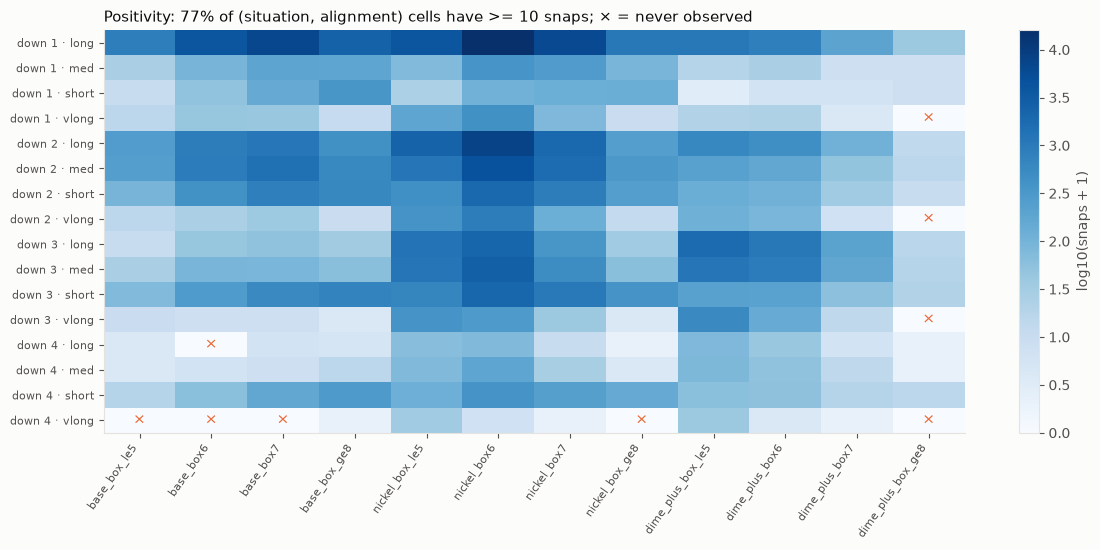

In [7]:
est = identify.identify_estimand(identify.build_causal_model(train, graph=graph))
print(f"DoWhy: backdoor-identified via {len(est.get_backdoor_variables())} adjustment variables")
pos_ = identify.check_positivity(train, cfg["positivity"]["min_count"])
cov = pos_["coverage"].set_index(pos_["strata_cols"])[list(range(ds.n_actions))]
cov.columns = order
fig, ax = plt.subplots(figsize=(12, 5.6)); ax.grid(False)
im = ax.imshow(np.log10(cov.values + 1), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(order)), order, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(cov)), [f"down {a} · {b}" for a, b in cov.index], fontsize=8)
for (i, j), v in np.ndenumerate(cov.values):
    if v == 0: ax.text(j, i, "×", ha="center", va="center", color=ORANGE, fontsize=11)
plt.colorbar(im, ax=ax, label="log10(snaps + 1)")
ax.set_title(f"Positivity: {pos_['pct_cells_supported']:.0%} of (situation, alignment) cells "
             f"have >= {pos_['min_count']} snaps; × = never observed", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

Pooling every defense is what makes positivity workable: most (situation, alignment) cells are
populated. The empty ones are mostly football — nobody shows dime with eight in the box on
third-and-long — and the policy is forbidden from recommending there.

## Step 3 — What coordinators actually call: π_b(A | S)

A calibrated gradient-boosted classifier over the twelve alignments. Its probabilities become
importance weights, so they are judged as probabilities: calibration is reported as a triple
(top-class confidence, every-class, and a proper scoring rule), and all diagnostics are
cross-fitted rather than in-sample.

In [8]:
beh, diag = fit_behavior_model(train, cfg)
print(f"accuracy {diag['oof_accuracy']:.3f} (majority {diag['majority_baseline']:.3f}) · "
      f"log loss {diag['oof_log_loss']:.3f} · ESS ratio {diag['ess_ratio']:.3f}")
print(f"confidence ECE {diag['confidence_ece']:.3f} · classwise ECE {diag['classwise_ece']:.3f} · "
      f"Brier {diag['brier']:.3f}")

accuracy 0.500 (majority 0.381) · log loss 1.375 · ESS ratio 0.211
confidence ECE 0.045 · classwise ECE 0.013 · Brier 0.644


## Step 4 — What would have happened: Q(S, A)

One gradient-boosted regressor over the pre-snap state *and* the alignment's two components
— package and front — rather than twelve separate models. Separate per-alignment models
estimate each cell with independent noise, inflating the spread between alignments; a policy
that maximizes Q then chases whichever cell is most overestimated. A pooled model lets a
rarely-shown alignment borrow from every alignment that shares its package or its front.

The question worth asking of any outcome model is not its fit but whether its *action effects*
behave like causes. Here are the two components' effects, by situation:

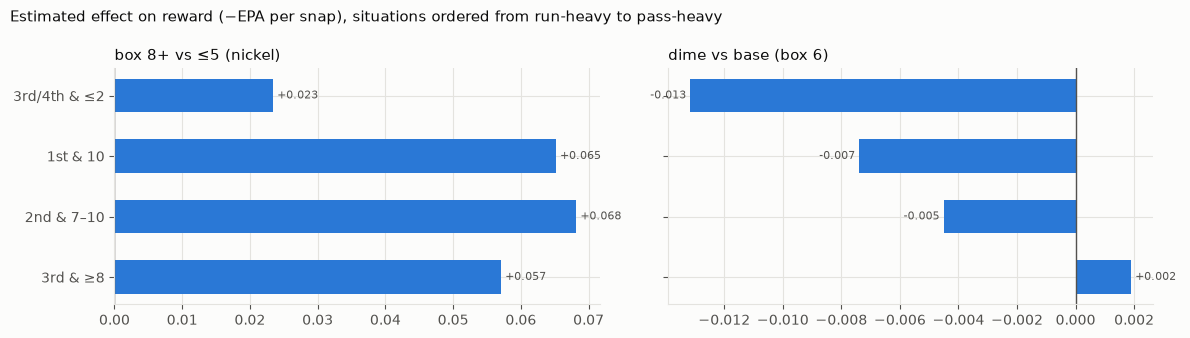

,run rate,box 8+ vs ≤5 (nickel),dime vs base (box 6)
3rd/4th & ≤2,65%,+0.0234,-0.0132
1st & 10,53%,+0.0652,-0.0074
2nd & 7–10,33%,+0.0682,-0.0045
3rd & ≥8,14%,+0.0571,+0.0019


In [9]:
q = fit_q_model(train, cfg)
dt = test.df; Qt = q.predict_all_actions(dt)
lab = {v: k for k, v in ds.action_labels.items()}
sit = {"3rd/4th & ≤2": (dt.down >= 3) & (dt.ydstogo <= 2),
       "1st & 10": (dt.down == 1) & (dt.ydstogo == 10),
       "2nd & 7–10": (dt.down == 2) & dt.ydstogo.between(7, 10),
       "3rd & ≥8": (dt.down == 3) & (dt.ydstogo >= 8)}
eff = pd.DataFrame({
    "run rate": [(dt.loc[m, "play_type"] == "run").mean() for m in sit.values()],
    "box 8+ vs ≤5 (nickel)": [(Qt[m, lab["nickel_box_ge8"]] - Qt[m, lab["nickel_box_le5"]]).mean() for m in sit.values()],
    "dime vs base (box 6)": [(Qt[m, lab["dime_plus_box6"]] - Qt[m, lab["base_box6"]]).mean() for m in sit.values()],
}, index=list(sit))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, col in zip(axes, eff.columns[1:]):
    ax.barh(eff.index, eff[col], color=BLUE, height=0.55); ax.axvline(0, color=INK2, lw=1)
    for y, v in enumerate(eff[col]):
        ax.text(v, y, f" {v:+.3f} ", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
    ax.set_title(col, loc="left", fontsize=11, color=INK)
axes[0].invert_yaxis()
fig.suptitle("Estimated effect on reward (−EPA per snap), situations ordered from run-heavy to pass-heavy",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()
eff.style.format({"run rate": "{:.0%}", "box 8+ vs ≤5 (nickel)": "{:+.4f}", "dime vs base (box 6)": "{:+.4f}"})

**Read these two panels differently.** The package effect behaves like a cause: base personnel
is better where runs are likely, dime is better on third-and-long, and the sign flips in
between. The box effect does not: it is positive everywhere and *smallest* exactly where runs
are most likely — backwards from how stacking the box against the run should work.

The likeliest explanation is that on passing downs a loaded box is mostly a **pressure look**,
so its estimated effect is travelling through the pressure call — which is part of the
alignment's total effect by construction here, but is not the run-fit mechanism the box is
usually credited with — possibly mixed with the unrecorded read. Separating the run-fit channel
from the pressure channel needs the coverage-and-pressure call modeled explicitly given the
alignment. Until then, the box effect is a total effect whose mechanism is unresolved, and it
should not be read as "stack the box."

## Step 5 — Scoring the behavior policy first

Before any off-policy estimate is believed, OPE has to reproduce the coordinators' own mean
reward. The outcome model is cross-fitted so the check is not scoring its own training rows.

In [10]:
mu = crossfit_q(train, cfg)
rec = behavior_recovery_check(train, q, beh, q_all=mu, weight_clip=clip, graph_version=gv)
print(f"empirical {rec['empirical_reward']:+.4f} · DM {rec['dm_under_pi_b']:+.4f} · "
      f"DR {rec['dr_under_pi_b']:+.4f} · gap {rec['recovery_gap']:.4f} -> "
      f"{'PASS' if rec['passes'] else 'FAIL'}")

empirical +0.0077 · DM +0.0084 · DR +0.0083 · gap 0.0006 -> PASS


## Step 6 — The recommendation, on a season it never saw

The policy starts from what the coordinator already does. In each situation it keeps the
coordinator's own mix of alignments, and departs only when some well-supported alignment's
advantage over that mix clears a **one-sided 99% lower bound**. The bound comes from refitting
the outcome model on resampled games: if a call's edge moves around from resample to resample,
the data has not established it, and the recommendation is "keep doing what you do".

Resampling only measures noise. It cannot see one bias the data does show: coordinators set the
box partly from a read of what the offense is about to do. Against the state's own prediction,
heavy boxes face more runs and light boxes fewer, and within each box runs and passes are worth
very different amounts to the defense. So a box departure also has to clear an **allowance for the
read**: twice the box's estimated bias relative to the coordinator's mix (excess runs faced ×
run-minus-pass value, per box, from the training seasons). The personnel package shows no such
footprint and gets no allowance.

It is then scored on the held-out season four ways: DM trusts the outcome model, IPW and SNIPW
trust the propensities, DR needs only one of them to be right.

In [11]:
ensemble = fit_q_ensemble(train, cfg)
policy = learn_safe_policy(train, q, beh, cfg, ensemble)
print(f"read allowance (x{policy.allowance_scale:g}), per box:")
print(policy.read_bias_table[["component", "n", "excess_run", "run_minus_pass", "bias"]]
      .to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
out = policy.act(dt)
a_te, r_te, pib = dt["action"].to_numpy(), dt["reward"].to_numpy(), beh.propensity(dt)
ladder = pd.concat([
    ope_ladder(Qt, pib, pib, a_te, r_te, clip, policy_name="behavior", graph_version=gv),
    ope_ladder(Qt, pib, out["policy_probs"], a_te, r_te, clip, policy_name="safe", graph_version=gv),
], ignore_index=True)
v_b = dr_policy_value(Qt, pib, pib, a_te, r_te, clip, policy_name="behavior", graph_version=gv)
v_p = dr_policy_value(Qt, pib, out["policy_probs"], a_te, r_te, clip, policy_name="safe", graph_version=gv)
dep = ~out["deferred"]
where = pd.Series(out["chosen"][dep]).map(ds.action_labels).value_counts(normalize=True)
print(f"keeps the coordinator's mix on {1 - dep.mean():.1%} of snaps · departs on {dep.mean():.1%}")
print("departures go to: " + ", ".join(f"{k} {v:.0%}" for k, v in where.head(4).items()))
ladder[["policy", "estimator", "value", "se", "support_share", "ess_ratio"]]

read allowance (x2), per box:
component     n  excess_run  run_minus_pass    bias
  box_le5 20100     -0.0501         -0.1424 +0.0071
     box6 51002     +0.0019         +0.0053 +0.0000
     box7 25488     +0.0179         +0.1047 +0.0019
  box_ge8  8631     +0.0620         +0.0939 +0.0058


keeps the coordinator's mix on 93.8% of snaps · departs on 6.2%
departures go to: base_box_ge8 37%, nickel_box7 37%, nickel_box_ge8 9%, nickel_box6 5%


,policy,estimator,value,se,support_share,ess_ratio
0,behavior,DM,+0.0043,+0.0009,+1.0000,+1.0000
1,behavior,IPW,-0.0052,+0.0074,+1.0000,+1.0000
2,behavior,SNIPW,-0.0052,+0.0074,+1.0000,+1.0000
3,behavior,DR-SN,-0.0036,+0.0074,+1.0000,+1.0000
4,safe,DM,+0.0075,+0.0009,+0.9482,+0.7117
5,safe,IPW,-0.0089,+0.0088,+0.9482,+0.7117
6,safe,SNIPW,-0.0090,+0.0089,+0.9482,+0.7117
7,safe,DR-SN,-0.0070,+0.0090,+0.9482,+0.7117


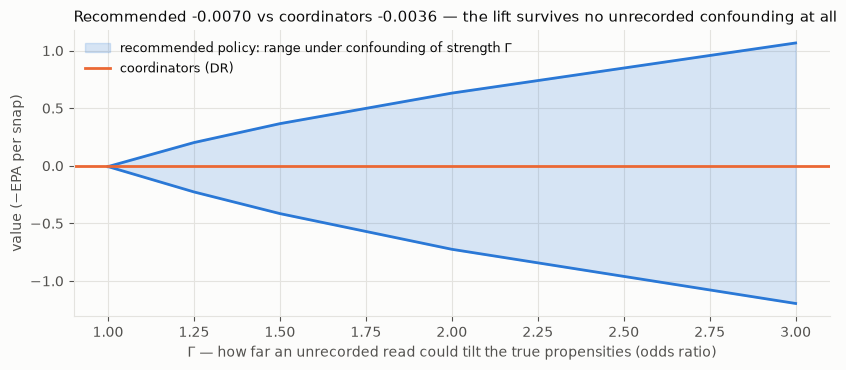

,policy,estimator,value,ci_lo,ci_hi,graph_version,robust_to_gamma
0,behavior,DR-SN,-0.0036,-0.0182,+0.0110,v3.2+8e2de51a8e2b,None
1,safe,DR-SN,-0.0070,-0.0246,+0.0105,v3.2+8e2de51a8e2b,None


In [12]:
sens = sensitivity_bounds(Qt, pib, out["policy_probs"], a_te, r_te, [1.0, 1.25, 1.5, 2.0, 3.0],
                          clip, compare_value=v_b.value, policy_name="safe")
attach_sensitivity(v_p, sens)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.fill_between(sens["gamma"], sens["v_lower"], sens["v_upper"], color=BLUE, alpha=0.18,
                label="recommended policy: range under confounding of strength Γ")
ax.plot(sens["gamma"], sens["v_lower"], color=BLUE, lw=2); ax.plot(sens["gamma"], sens["v_upper"], color=BLUE, lw=2)
ax.axhline(v_b.value, color=ORANGE, lw=2, label="coordinators (DR)")
ax.set_xlabel("Γ — how far an unrecorded read could tilt the true propensities (odds ratio)")
ax.set_ylabel("value (−EPA per snap)"); ax.legend(frameon=False, loc="upper left", fontsize=9)
g = v_p.robust_to_gamma
verdict = ("the lift survives no unrecorded confounding at all" if not g or g <= 1.0
           else f"the lift survives confounding up to Γ = {g}")
ax.set_title(f"Recommended {v_p.value:+.4f} vs coordinators {v_b.value:+.4f} — {verdict}",
             loc="left", fontsize=11)
plt.tight_layout(); plt.show()
pd.DataFrame([v_b.to_record(), v_p.to_record()])[["policy", "estimator", "value", "ci_lo", "ci_hi", "graph_version", "robust_to_gamma"]]

The recommended policy and the coordinators are **statistically indistinguishable** on the
held-out season. All four rungs of the ladder agree to within their error — no nuisance model is
misbehaving — so this is a real null, not a broken estimator.

The departures are the interesting part. The policy leaves the coordinator on roughly one snap in
sixteen, almost all of them toward a heavier box (seven or eight-plus). Both extremes of the box
carry read bias — an eight-man box gets the runs it was set for, a light box avoids the runs that
would hurt it — at roughly 0.006–0.007 per snap each, and the allowance makes every departure pay
twice that before it counts. What it covers is only the run/pass channel of the read, the one the
data shows; any other part of the coordinator's read is still invisible to it, which is what the
sensitivity band is for.


## Step 7 — The regression gate

The candidate is scored against the behavior-constrained greedy baseline on the same held-out
snaps with the same models, so the difference is paired and the shared noise cancels. The
gate blocks only on a proven deterioration past the margin.

In [13]:
cmp = compare_to_baseline(test, q, beh, cfg, ensemble=ensemble, candidate=policy)
print(cmp.report())

  V_DR(greedy_baseline) = -0.0116
  V_DR(safe_candidate ) = -0.0070
  paired difference     = +0.0046  95% CI [-0.0390, +0.0481]  (n=34449)
  non-inferiority margin= 0.0200
  verdict: NO CHANGE DETECTED  ->  gate passes


The greedy baseline — pure argmax Q over supported alignments — scores *below* the coordinators:
maximizing a noisy Q selects its most overestimated entries. Deferring to the coordinators' own
mix wherever the edge is not established is what keeps the recommendation from paying for that
noise.

## Recommendations in the situations that matter

In [14]:
rows = []
for name, where in [("3rd/4th & short", (dt.down >= 3) & (dt.ydstogo <= 2)),
                    ("goal-to-go inside the 5", dt.yardline_100 <= 5),
                    ("1st & 10", (dt.down == 1) & (dt.ydstogo == 10)),
                    ("3rd & long", (dt.down == 3) & (dt.ydstogo >= 8))]:
    pool = dt[where]
    res = policy.act(pool)
    dep = ~res["deferred"]
    top = pd.Series(res["chosen"][dep]).map(ds.action_labels).value_counts(normalize=True)
    dc = pool["action_label"].value_counts(normalize=True)
    rows.append({"situation": name, "snaps": len(pool),
                 "keeps the usual mix": f"{1 - dep.mean():.0%}",
                 "departs to": f"{top.index[0]} ({top.iloc[0]:.0%} of departures)" if dep.any() else "—",
                 "coordinators' most-common": f"{dc.index[0]} ({dc.iloc[0]:.0%})"})
pd.DataFrame(rows)

,situation,snaps,keeps the usual mix,departs to,coordinators' most-common
0,3rd/4th & short,2013,96%,base_box_ge8 (29% of departures),nickel_box6 (33%)
1,goal-to-go inside the 5,1360,95%,base_box_ge8 (40% of departures),base_box_ge8 (27%)
2,1st & 10,13464,93%,base_box_ge8 (52% of departures),nickel_box6 (38%)
3,3rd & long,2792,97%,nickel_box7 (33% of departures),nickel_box6 (35%)


## Validation aside — a league whose answer is known

The same pipeline, run on a simulated league built with deterrence: a heavier alignment is good
against the run, bad against the pass, *and* makes the offense less likely to run at all. A
hidden read drives both the coordinator's call and the outcome. Because the true value of any
policy is computable, three claims become checkable against truth rather than against another
estimate.

In [15]:
scfg = {**cfg, "data": {**cfg["data"]}}
syn = build_dataset(generate_synthetic_alignment(9000, seed=11, seasons=S), scfg)
s_tr, s_te = time_aware_split(syn, cfg["data"]["holdout_season"])
s_beh, _ = fit_behavior_model(s_tr, scfg); s_q = fit_q_model(s_tr, scfg)
s_out = learn_safe_policy(s_tr, s_q, s_beh, scfg, fit_q_ensemble(s_tr, scfg)).act(s_te.df)
sd = s_te.df; sa = sd["action"].to_numpy(); sr = sd["reward"].to_numpy()
sQ = s_q.predict_all_actions(sd); spib = s_beh.propensity(sd)
dr_b = dr_policy_value(sQ, spib, spib, sa, sr, clip)
band = sensitivity_bounds(sQ, spib, s_out["policy_probs"], sa, sr, [1.0, 3.0], clip).set_index("gamma")
played = np.where(s_out["deferred"], sa, s_out["chosen"])  # deferring = the logged call
t_b, t_p = true_alignment_value(sd, sa), true_alignment_value(sd, played)
pd.DataFrame({
    "claim": ["recommended policy beats the coordinator in truth",
              "DR recovers the coordinator's true value",
              "the Γ=3 band contains the recommended policy's true value"],
    "evidence": [f"true {t_p:+.4f} vs {t_b:+.4f}",
                 f"DR {dr_b.value:+.4f} ± {1.96*dr_b.se:.4f} vs true {t_b:+.4f}",
                 f"[{band.loc[3.0,'v_lower']:+.4f}, {band.loc[3.0,'v_upper']:+.4f}] ∋ {t_p:+.4f}"],
    "holds": [t_p > t_b, abs(dr_b.value - t_b) <= 3 * dr_b.se,
              band.loc[3.0, "v_lower"] <= t_p <= band.loc[3.0, "v_upper"]],
})

,claim,evidence,holds
0,recommended policy beats the coordinator in truth,true +0.0271 vs +0.0179,True
1,DR recovers the coordinator's true value,DR +0.0196 ± 0.0270 vs true +0.0179,True
2,the Γ=3 band contains the recommended policy's...,"[-0.5348, +0.5950] ∋ +0.0271",True


All three are also pinned as regression tests. One caution the simulation makes concrete: on a
holdout this small, DR's error on a *new* policy's value is about as large as the true gain,
so a single point estimate there can land on either side of the truth. The real holdout is
roughly sixteen times larger, which narrows that error to about ±0.01–0.02 EPA per snap — enough
to rule out a large gain, not a small one.

## Summary

- **Every snap is in.** Runs included, all defenses pooled: short yardage and goal line are
  learnable, and the alignment's deterrence effect is inside the estimand rather than
  selected away.
- **The alignment is a real, callable action** — chosen before the snap, observed on ~100% of
  plays.
- **The graph is tested, not just drawn.** Its independence claims are checked against the data
  and confirmed on a season it was not revised on; the one claim no data can check is named.
- **The recommended policy does no harm and no measurable good.** It keeps the coordinators'
  own mix unless a call's edge clears a 99% bound, matches them on the held-out season within
  error, and the gap either way is small enough for a mild unrecorded read to account for. Pure
  argmax-Q does worse.
- **The remaining risk is bias, not noise.** The calls the bound lets through are mostly heavy
  boxes, whose edge is partly the coordinator's read of a coming run.
- **The package effect looks causal; the box effect does not yet.** Its estimated effect is
  largest on passing downs, which points at the pressure call rather than run fits.

Next: model the coverage-and-pressure call given the alignment, which both separates the box's
two channels and completes the factored recommendation; then test whether the effects that
survive transfer across teams and seasons.